# Binary and discrete characteristics

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *

In [2]:
chars = char_names()
df = add_n_missing(is_universe(), chars)
rows = []
for c in chars:
    s = df[c].drop_nulls()
    vc = s.value_counts(sort=True)
    rows.append({"char": c, "missing": df[c].null_count() / df.height, "n_unique": s.n_unique(),
                 "most_common_value": vc[c][0], "most_common_share": vc["count"][0] / s.len()})
disc = pl.DataFrame(rows)

## Characteristics with at most 20 distinct values

In [3]:
disc.filter(pl.col("n_unique") <= 20).sort("n_unique")

char,missing,n_unique,most_common_value,most_common_share
str,f64,i64,f64,f64
"""convind""",0.1796,2,0.0000,0.8579
"""divi""",0.2217,2,0.0000,0.9751
"""divo""",0.2217,2,0.0000,0.9723
"""rd""",0.2217,2,0.0000,0.9103
"""securedind""",0.1796,2,0.0000,0.5416
"""sin""",0.1796,2,0.0000,0.9878
"""nincr""",0.2201,9,0.0000,0.4336
"""ms""",0.2360,9,5.0000,0.2210
"""ps""",0.2217,10,5.0000,0.2262


## Continuous characteristics with a large point mass

In [4]:
disc.filter((pl.col("n_unique") > 20) & (pl.col("most_common_share") > 0.1)).sort("most_common_share", descending=True)

char,missing,n_unique,most_common_value,most_common_share
str,f64,i64,f64,f64
"""dy""",0.1866,27056,0.0000,0.3210
"""secured""",0.4554,15637,0.0000,0.3099
"""rd_sale""",0.6346,13523,0.0000,0.2587
"""rd_mve""",0.6336,13635,0.0000,0.2580
"""chinv""",0.2480,30241,0.0000,0.1873
"""hire""",0.2321,24481,0.0000,0.1032


## Binary flags: share equal to 1 (non-missing rows)

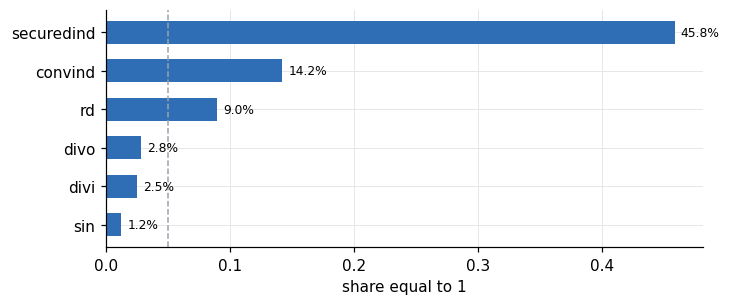

In [5]:
flags = disc.filter(pl.col("n_unique") == 2)["char"].to_list()
share1 = pl.DataFrame({"flag": flags, "share_one": [df[f].drop_nulls().mean() for f in flags]}).sort("share_one")
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(share1["flag"], share1["share_one"], color=BLUE, height=0.6)
for y, v in enumerate(share1["share_one"]):
    ax.text(v + 0.005, y, f"{v:.1%}", va="center", fontsize=8)
ax.axvline(0.05, color=GREY, lw=1, ls="--"); ax.set_xlabel("share equal to 1"); plt.show()

## Score distributions: ps, ms, nincr

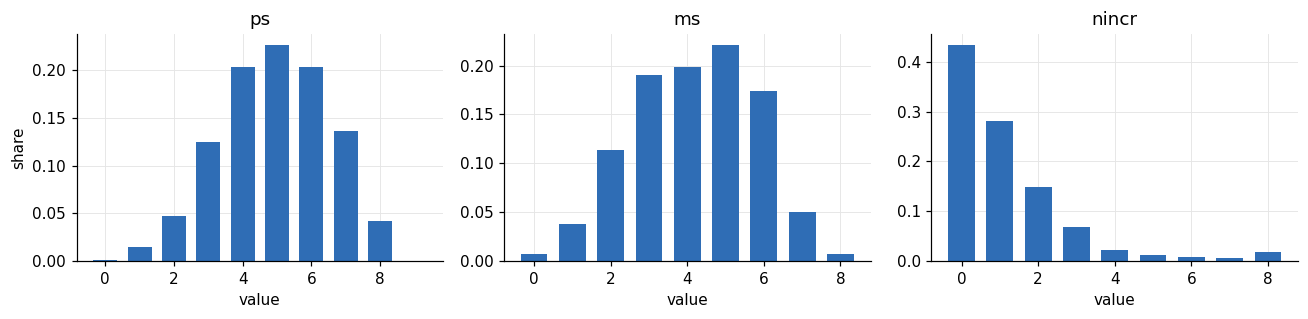

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, c in zip(axes, ["ps", "ms", "nincr"]):
    vc = df[c].drop_nulls().value_counts().sort(c)
    ax.bar(vc[c], vc["count"] / vc["count"].sum(), color=BLUE, width=0.7)
    ax.set_title(c); ax.set_xlabel("value")
axes[0].set_ylabel("share"); plt.tight_layout(); plt.show()

## securedind vs secured

In [7]:
(df.with_columns(pl.when(pl.col("secured").is_null()).then(pl.lit("missing"))
                   .when(pl.col("secured") > 0).then(pl.lit("> 0")).otherwise(pl.lit("= 0")).alias("secured"))
   .group_by("secured", "securedind").len().sort("secured", "securedind"))

secured,securedind,len
str,f64,u32
"""= 0""",0.0000,89904
"""> 0""",1.0000,200218
"""missing""",null,95697
"""missing""",0.0000,146778
"""missing""",1.0000,131


## rd vs rd_mve vs rd_sale

In [8]:
def state(c):
    return pl.when(pl.col(c).is_null()).then(pl.lit("missing")).when(pl.col(c) == 0).then(pl.lit("0")).otherwise(pl.lit("> 0")).alias(c)
df.select(pl.col("rd"), state("rd_mve"), state("rd_sale")).group_by("rd", "rd_mve", "rd_sale").len().sort("len", descending=True)

rd,rd_mve,rd_sale,len
f64,str,str,u32
0.0000,"""missing""","""missing""",229165
null,"""missing""","""missing""",108242
0.0000,"""> 0""","""> 0""",101000
0.0000,"""0""","""0""",46947
1.0000,"""> 0""","""> 0""",36899
null,"""> 0""","""> 0""",6335
null,"""0""","""0""",3368
1.0000,"""> 0""","""missing""",266
0.0000,"""> 0""","""missing""",210


## Industry-level characteristics: distinct values within each (month, sic2) and within-group spread

In [9]:
rows = []
for c in ["herf", "indmom", "mve_ia", "bm_ia", "cfp_ia", "chpmia", "chatoia", "chempia", "pchcapx_ia"]:
    g = df.filter(pl.col(c).is_not_null()).group_by("DATE", "sic2").agg(
        pl.col(c).n_unique().alias("nu"), pl.col(c).std().alias("sd_within"))
    sd_all = df.group_by("DATE").agg(pl.col(c).std())[c].median()
    rows.append({"char": c, "groups_1_value": (g["nu"] == 1).mean(), "groups_2_values": (g["nu"] == 2).mean(),
                 "groups_3plus_values": (g["nu"] >= 3).mean(),
                 "median_distinct_per_month": df.group_by("DATE").agg(pl.col(c).drop_nulls().n_unique())[c].median(),
                 "within_group_sd_over_cross_section_sd": g["sd_within"].drop_nulls().median() / sd_all})
pl.DataFrame(rows)

char,groups_1_value,groups_2_values,groups_3plus_values,median_distinct_per_month,within_group_sd_over_cross_section_sd
str,f64,f64,f64,f64,f64
"""herf""",0.3822,0.6091,0.0087,111.0000,0.0070
"""indmom""",0.3915,0.5979,0.0107,63.0000,0.0839
"""mve_ia""",0.0402,0.0128,0.9470,2305.0000,0.4642
"""bm_ia""",0.0477,0.0157,0.9367,2334.0000,0.0805
"""cfp_ia""",0.0418,0.0195,0.9387,2174.0000,0.6164
"""chpmia""",0.0417,0.0179,0.9404,2274.0000,0.0169
"""chatoia""",0.0423,0.0242,0.9336,2169.0000,0.9095
"""chempia""",0.0449,0.0211,0.9340,2025.0000,0.5822
"""pchcapx_ia""",0.0412,0.0190,0.9398,2071.0000,0.1862
